# 03 — Early Fusion

**Project 2.2 — Cross-Modal Retrieval: Mobile App Screens and Text Summaries**

Tess Santhosh (a2910201) · COMP 1030 Multimodal Data Analytics, Adelaide University

Implements two techniques: a Ridge regression baseline and an early-fusion MLP. Both combine the two modalities before scoring, Ridge by a linear mapping between embedding spaces, the MLP by concatenating both embeddings into one network unlike notebook 04’s dual encoder, which encodes each modality separately and compares them afterwards. It matters because the early-fusion scorer can't cache a candidate embedding, it must re-run the network once per (image, caption) pair, so answering a query costs one forward pass per candidate. This notebook measures that cost directly and it's compared against the dual encoder's cost later.

Re-extracts the same ResNet-50/BERT features as notebook 02 through `src/utils.py`, so this notebook runs standalone.

**Outputs:**
- `results/figures/fig4_ridge_score_heatmap.png`, `fig5_early_fusion_loss_curve.png`, `fig6_early_fusion_score_heatmap.png`
- `results/tables/early_fusion_metrics.csv`, `early_fusion_parameter_counts.csv`

## Setup

In [ ]:
#repo setup
import os, sys, subprocess

REPO_URL = "https://github.com/tesssanthosh/cross-modal-retrieval-2.2.git"
REPO_DIR = "/content/cross-modal-retrieval-2.2"

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())


Working directory: /content/cross-modal-retrieval-2.2


In [ ]:
!pip install -q -r requirements.txt
!pip install -q datasets


In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

from src.utils import (
    count_parameters, retrieval_report, cosine_score_matrix,
    load_rico_splits_with_features,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)


Device: cuda
GPU: Tesla T4


## Load data and features

Repeats notebook 02’s extraction here as well for
this notebook to run standalone

In [ ]:
data, resnet, bert = load_rico_splits_with_features(DEVICE)

for split_name, d in data.items():
    print(f"{split_name}: {d['image_features'].shape[0]} screens, "
          f"{len(d['flat_df'])} captions, eval set {len(d['eval_df'])} screens")


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (35 outputs left out)

BERT features:   0%|          | 0/93 [00:00<?, ?it/s]

ResNet-50 features:   0%|          | 0/68 [00:00<?, ?it/s]

BERT features:   0%|          | 0/169 [00:00<?, ?it/s]

train: 15743 screens, 78715 captions, eval set 15743 screens
val: 2364 screens, 11820 captions, eval set 2364 screens
test: 4310 screens, 21550 captions, eval set 4310 screens


## Standardise features (training-split statistics only)

The frozen features aren’t zero-centred and have very different per-dimension scales and this matters for Ridge, since its L2 penalty regularises every dimension equally. Mean/std are computed on train only and applied unchanged to val/test, so no held-out information leaks in.


In [ ]:
img_mu = data["train"]["image_features"].mean(0, keepdim=True)
img_sd = data["train"]["image_features"].std(0, keepdim=True).clamp(min=1e-6)
txt_mu = data["train"]["flat_text_features"].mean(0, keepdim=True)
txt_sd = data["train"]["flat_text_features"].std(0, keepdim=True).clamp(min=1e-6)

for split_name, d in data.items():
    d["image_features"] = (d["image_features"] - img_mu) / img_sd
    d["flat_text_features"] = (d["flat_text_features"] - txt_mu) / txt_sd
    d["eval_text_features"] = (d["eval_text_features"] - txt_mu) / txt_sd

print("Features standardised using training-split mean/std.")


Features standardised using training-split mean/std.


In [ ]:
# screenId to row index lookup
# used to repeat each screen's image feature per caption
screen_idx = {
    split_name: {int(sid): i for i, sid in enumerate(d["screenId"].tolist())}
    for split_name, d in data.items()
}


def build_xy(split_name):
    # returns image and text features, one row per caption, in the same order
    d = data[split_name]
    idx = d["flat_df"]["screenId"].map(lambda s: screen_idx[split_name][int(s)]).to_numpy()
    X_img = d["image_features"][idx].numpy()
    Y_txt = d["flat_text_features"].numpy()
    return X_img, Y_txt


## Technique 1 — Ridge regression baseline

Linear model predicting one modality's embedding from the other. Two separate models are fit (image→text, text→image), since a linear map isn't generally invertible, so each direction is scored separately below, not through `retrieval_report`'s transpose shortcut.

`alpha` is selected on **validation** only, by Recall@10 specifically, the actual metric this project is judged on, not a weaker proxy like cosine similarity.

In [ ]:
X_img_train, Y_txt_train = build_xy("train")
X_img_val, Y_txt_val = build_xy("val")

print("Train pairs:", X_img_train.shape, Y_txt_train.shape)
print("Val pairs:  ", X_img_val.shape, Y_txt_val.shape)


Train pairs: (78715, 2048) (78715, 768)
Val pairs:   (11820, 2048) (11820, 768)


In [ ]:
from src.utils import recall_at_k

# val eval set which is used to select alpha by the real target metric
img_val_eval = data["val"]["image_features"]
txt_val_eval = data["val"]["eval_text_features"]

ALPHAS = [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
best_alpha_i2t, best_score_i2t = None, -1.0
best_alpha_t2i, best_score_t2i = None, -1.0

for alpha in ALPHAS:
    ridge_i2t = Ridge(alpha=alpha).fit(X_img_train, Y_txt_train)
    pred_txt_val = torch.tensor(ridge_i2t.predict(img_val_eval.numpy()), dtype=torch.float32)
    r10_i2t = recall_at_k(cosine_score_matrix(pred_txt_val, txt_val_eval), 10)

    ridge_t2i = Ridge(alpha=alpha).fit(Y_txt_train, X_img_train)
    pred_img_val = torch.tensor(ridge_t2i.predict(txt_val_eval.numpy()), dtype=torch.float32)
    r10_t2i = recall_at_k(cosine_score_matrix(pred_img_val, img_val_eval), 10)

    print(f"alpha={alpha:>8}: image->text val R@10={r10_i2t:.4f} | "
          f"text->image val R@10={r10_t2i:.4f}")

    if r10_i2t > best_score_i2t:
        best_alpha_i2t, best_score_i2t = alpha, r10_i2t
    if r10_t2i > best_score_t2i:
        best_alpha_t2i, best_score_t2i = alpha, r10_t2i

print(f"\nSelected alpha (by validation Recall@10): "
      f"image->text={best_alpha_i2t}, text->image={best_alpha_t2i}")


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.17451e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


alpha=     0.1: image->text val R@10=0.0478 | text->image val R@10=0.0499


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.23893e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


alpha=     1.0: image->text val R@10=0.0482 | text->image val R@10=0.0499
alpha=    10.0: image->text val R@10=0.0482 | text->image val R@10=0.0499
alpha=   100.0: image->text val R@10=0.0482 | text->image val R@10=0.0503
alpha=  1000.0: image->text val R@10=0.0474 | text->image val R@10=0.0499
alpha= 10000.0: image->text val R@10=0.0520 | text->image val R@10=0.0482

Selected alpha (by validation Recall@10): image->text=10000.0, text->image=100.0


In [ ]:
ridge_i2t = Ridge(alpha=best_alpha_i2t).fit(X_img_train, Y_txt_train)
ridge_t2i = Ridge(alpha=best_alpha_t2i).fit(Y_txt_train, X_img_train)
print("Final Ridge models fit on the full training set.")


Final Ridge models fit on the full training set.


### Ridge retrieval evaluation

For each split: predict the target modality from the source modality, then rank by cosine similarity against the real embeddings. recall_at_k is called directly on each direction’s score matrix, not via retrieval_report.


In [ ]:
from src.utils import recall_at_k
from sklearn.metrics import roc_auc_score


def ridge_eval(split_name):
    d = data[split_name]
    img_eval = d["image_features"]
    txt_eval = d["eval_text_features"]

    pred_txt = torch.tensor(ridge_i2t.predict(img_eval.numpy()), dtype=torch.float32)
    scores_i2t = cosine_score_matrix(pred_txt, txt_eval)

    pred_img = torch.tensor(ridge_t2i.predict(txt_eval.numpy()), dtype=torch.float32)
    scores_t2i = cosine_score_matrix(pred_img, img_eval)

    out = {}
    for k in (1, 5, 10):
        out[f"R@{k} image->text"] = recall_at_k(scores_i2t, k)
        out[f"R@{k} text->image"] = recall_at_k(scores_t2i, k)
    is_match = torch.eye(len(scores_i2t)).flatten().numpy()
    out["AUC image->text"] = roc_auc_score(is_match, scores_i2t.flatten().numpy())
    out["AUC text->image"] = roc_auc_score(is_match, scores_t2i.flatten().numpy())
    return out, scores_i2t


ridge_val_metrics, _ = ridge_eval("val")
ridge_test_metrics, ridge_test_scores_i2t = ridge_eval("test")

print("Ridge — validation:"); print(ridge_val_metrics)
print("\nRidge — test:"); print(ridge_test_metrics)


Ridge — validation:
{'R@1 image->text': 0.008037225343286991, 'R@1 text->image': 0.009306260384619236, 'R@5 image->text': 0.032148901373147964, 'R@5 text->image': 0.032148901373147964, 'R@10 image->text': 0.05203045532107353, 'R@10 text->image': 0.05033840984106064, 'AUC image->text': np.float64(0.7221005532675775), 'AUC text->image': np.float64(0.716148239591768)}

Ridge — test:
{'R@1 image->text': 0.005568445660173893, 'R@1 text->image': 0.006496519781649113, 'R@5 image->text': 0.019953595474362373, 'R@5 text->image': 0.024361949414014816, 'R@10 image->text': 0.0329466350376606, 'R@10 text->image': 0.03851507976651192, 'AUC image->text': np.float64(0.7227845991226054), 'AUC text->image': np.float64(0.7108514541468651)}


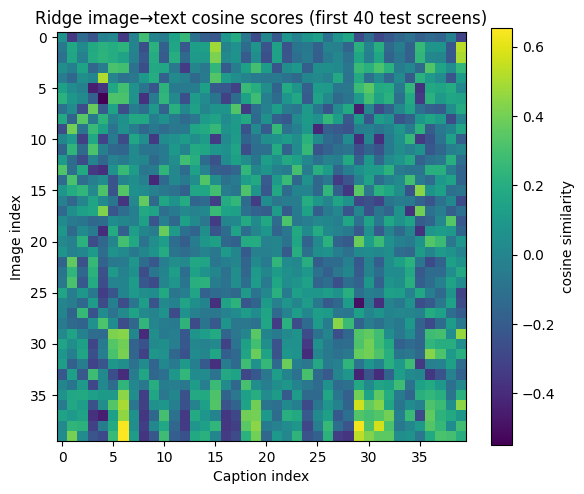

In [ ]:
# score heatmap of a small block of the test matrix so the diagonal pattern is visible
N_SHOW = 40
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(ridge_test_scores_i2t[:N_SHOW, :N_SHOW], cmap="viridis")
ax.set_title(f"Ridge image→text cosine scores (first {N_SHOW} test screens)")
ax.set_xlabel("Caption index"); ax.set_ylabel("Image index")
fig.colorbar(im, ax=ax, label="cosine similarity")
fig.tight_layout()
fig.savefig("results/figures/fig4_ridge_score_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Technique 2 — Early-fusion MLP (concatenate + project)

Concatenates `[image_embedding ; caption_embedding]` into one 2816-d vector and passes it through a small MLP, and outputs a single compatibility score. Trained as binary classification: real pairs labelled 1, a mismatched caption from the same batch labelled 0.

Early stopping is on validation loss, not retrieval score. Full retrieval metrics are only computed once, after training, since they're expensive here.

Each positive is trained against 4 negatives (cyclic shifts within the batch), not 1 a single negative overfit after one epoch in an earlier run. `pos_weight` rebalances for the resulting 1:4 ratio.

In [ ]:
class EarlyFusionScorer(nn.Module):
    def __init__(self, image_dim=2048, text_dim=768, hidden=(512, 128), dropout=0.2):
        super().__init__()
        dims = [image_dim + text_dim] + list(hidden)
        layers = []
        for i in range(len(dims) - 1):
            layers += [nn.Linear(dims[i], dims[i + 1]), nn.ReLU(), nn.Dropout(dropout)]
        layers.append(nn.Linear(dims[-1], 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


class PairDataset(Dataset):
    # one row per (image, caption) pair
    def __init__(self, split_name):
        self.flat_df = data[split_name]["flat_df"].reset_index(drop=True)
        self.image_features = data[split_name]["image_features"]
        self.text_features = data[split_name]["flat_text_features"]
        self.idx_lookup = screen_idx[split_name]

    def __len__(self):
        return len(self.flat_df)

    def __getitem__(self, i):
        screen_id = int(self.flat_df.iloc[i]["screenId"])
        img = self.image_features[self.idx_lookup[screen_id]]
        txt = self.text_features[i]
        return img, txt


BATCH_SIZE = 256
train_loader = DataLoader(PairDataset("train"), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(PairDataset("val"), batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

model = EarlyFusionScorer().to(DEVICE)
print(f"EarlyFusionScorer: {count_parameters(model):,} trainable parameters")


EarlyFusionScorer: 1,508,097 trainable parameters


In [ ]:
NUM_NEGATIVES = 4


def pairwise_batch_loss(model, imgs, txts, criterion, num_negatives=NUM_NEGATIVES):
    #builds one positive + several in batch negative pairs
    b = imgs.shape[0]
    assert num_negatives < b, "num_negatives must be smaller than the batch size"
    pos_in = torch.cat([imgs, txts], dim=1)
    neg_ins = [torch.cat([imgs, txts.roll(shifts=shift, dims=0)], dim=1)
               for shift in range(1, num_negatives + 1)]
    x = torch.cat([pos_in] + neg_ins, dim=0)
    y = torch.cat([torch.ones(b), torch.zeros(b * num_negatives)]).to(imgs.device)
    logits = model(x)
    return criterion(logits, y)


opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
# pos_weight rebalances the 1:NUM_NEGATIVES ratio
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(NUM_NEGATIVES), device=DEVICE))

MAX_EPOCHS = 20
PATIENCE = 4
best_val_loss = float("inf")
bad_epochs = 0
best_state = None
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for imgs, txts in train_loader:
        imgs, txts = imgs.to(DEVICE), txts.to(DEVICE)
        opt.zero_grad()
        loss = pairwise_batch_loss(model, imgs, txts, criterion)
        loss.backward()
        opt.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses = []
    with torch.no_grad():
        for imgs, txts in val_loader:
            imgs, txts = imgs.to(DEVICE), txts.to(DEVICE)
            val_losses.append(pairwise_batch_loss(model, imgs, txts, criterion).item())

    train_loss = sum(train_losses) / len(train_losses)
    val_loss = sum(val_losses) / len(val_losses)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"epoch {epoch:2d}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        bad_epochs = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f}).")
            break

model.load_state_dict(best_state)


epoch  1: train_loss=0.9148  val_loss=1.1673
epoch  2: train_loss=0.7914  val_loss=1.2113
epoch  3: train_loss=0.7376  val_loss=1.2437
epoch  4: train_loss=0.7025  val_loss=1.2561
epoch  5: train_loss=0.6704  val_loss=1.2962
Early stopping at epoch 5 (best val_loss=1.1673).


<All keys matched successfully>

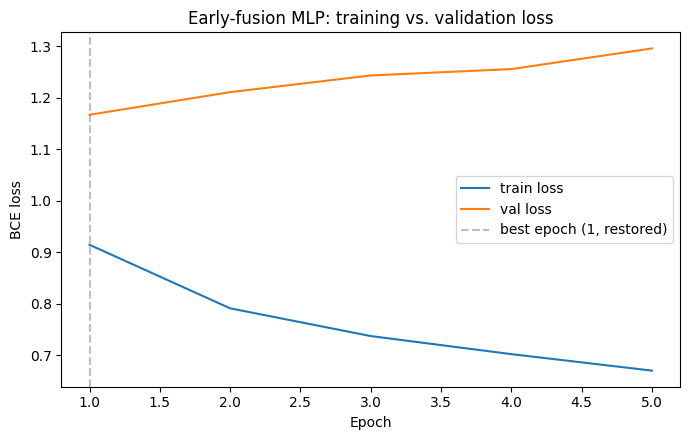

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
epochs = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1  # the epoch actually restored above
ax.plot(epochs, history["train_loss"], label="train loss")
ax.plot(epochs, history["val_loss"], label="val loss")
ax.axvline(best_epoch, color="gray", linestyle="--", alpha=0.5,
           label=f"best epoch ({best_epoch}, restored)")
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE loss")
ax.set_title("Early-fusion MLP: training vs. validation loss")
ax.legend()
fig.tight_layout()
fig.savefig("results/figures/fig5_early_fusion_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()


### Early-fusion retrieval evaluation

Unlike the dual encoder in the next notebook 04, this scorer has no standalone embedding to cache, it scores all N×N (image, caption) pairs directly and timed deliberately for comparison against the dual encoder in notebook 05.

Train retrieval is evaluated on a 2000-screen subsample, not the full 15,743 (~247M pairs), for compute cost reasons.

In [ ]:
@torch.no_grad()
def score_matrix_concat(model, image_feats, text_feats, device, q_chunk=128, c_chunk=512):
    model.eval()
    n, m = image_feats.shape[0], text_feats.shape[0]
    scores = torch.empty(n, m)
    image_feats = image_feats.to(device)
    text_feats = text_feats.to(device)
    for qs in range(0, n, q_chunk):
        qe = min(qs + q_chunk, n)
        img_block = image_feats[qs:qe]
        for cs in range(0, m, c_chunk):
            ce = min(cs + c_chunk, m)
            txt_block = text_feats[cs:ce]
            q, c = img_block.shape[0], txt_block.shape[0]
            img_rep = img_block.unsqueeze(1).expand(q, c, img_block.shape[1]).reshape(q * c, -1)
            txt_rep = txt_block.unsqueeze(0).expand(q, c, txt_block.shape[1]).reshape(q * c, -1)
            logits = model(torch.cat([img_rep, txt_rep], dim=1)).view(q, c)
            scores[qs:qe, cs:ce] = logits.cpu()
    return scores


def timed_early_fusion_eval(split_name, max_screens=None):
    d = data[split_name]
    img, txt = d["image_features"], d["eval_text_features"]
    if max_screens is not None and img.shape[0] > max_screens:
        sel = torch.randperm(img.shape[0])[:max_screens]
        img, txt = img[sel], txt[sel]

    t0 = time.time()
    scores = score_matrix_concat(model, img, txt, DEVICE)
    elapsed = time.time() - t0

    report = retrieval_report(scores, ks=(1, 5, 10))
    n_pairs = img.shape[0] * txt.shape[0]
    report["n_screens_scored"] = img.shape[0]
    report["n_pairs_scored"] = n_pairs
    report["scoring_time_sec"] = round(elapsed, 2)
    report["ms_per_pair"] = round(1000 * elapsed / n_pairs, 4)
    return report, scores


ef_train_metrics, _ = timed_early_fusion_eval("train", max_screens=2000)
ef_val_metrics, _ = timed_early_fusion_eval("val")
ef_test_metrics, ef_test_scores = timed_early_fusion_eval("test")

print("Early fusion — train (2,000-screen subsample):"); print(ef_train_metrics)
print("\nEarly fusion — validation:"); print(ef_val_metrics)
print("\nEarly fusion — test:"); print(ef_test_metrics)


Early fusion — train (2,000-screen subsample):
{'R@1 image->text': 0.007499999832361937, 'R@1 text->image': 0.006000000052154064, 'R@5 image->text': 0.03700000047683716, 'R@5 text->image': 0.029999999329447746, 'R@10 image->text': 0.06800000369548798, 'R@10 text->image': 0.05649999901652336, 'AUC': np.float64(0.8221099180840419), 'n_screens_scored': 2000, 'n_pairs_scored': 4000000, 'scoring_time_sec': 3.77, 'ms_per_pair': 0.0009}

Early fusion — validation:
{'R@1 image->text': 0.008037225343286991, 'R@1 text->image': 0.006345177534967661, 'R@5 image->text': 0.027495769783854485, 'R@5 text->image': 0.023265652358531952, 'R@10 image->text': 0.05033840984106064, 'R@10 text->image': 0.04526226595044136, 'AUC': np.float64(0.7884934534407417), 'n_screens_scored': 2364, 'n_pairs_scored': 5588496, 'scoring_time_sec': 5.26, 'ms_per_pair': 0.0009}

Early fusion — test:
{'R@1 image->text': 0.004176334012299776, 'R@1 text->image': 0.0034802784211933613, 'R@5 image->text': 0.01740139164030552, 'R@5

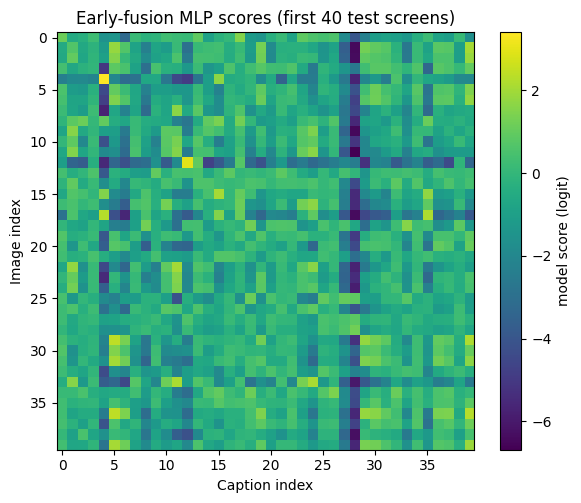

In [ ]:
N_SHOW = 40
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(ef_test_scores[:N_SHOW, :N_SHOW], cmap="viridis")
ax.set_title(f"Early-fusion MLP scores (first {N_SHOW} test screens)")
ax.set_xlabel("Caption index"); ax.set_ylabel("Image index")
fig.colorbar(im, ax=ax, label="model score (logit)")
fig.tight_layout()
fig.savefig("results/figures/fig6_early_fusion_score_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Save results


In [ ]:
rows = []
for split_name, m in [("val", ridge_val_metrics), ("test", ridge_test_metrics)]:
    row = {"technique": "Ridge regression (baseline)", "split": split_name}
    row.update(m)
    rows.append(row)

for split_name, m in [("train_subsample_2000", ef_train_metrics), ("val", ef_val_metrics),
                       ("test", ef_test_metrics)]:
    row = {"technique": "Early fusion (MLP)", "split": split_name}
    row.update(m)
    rows.append(row)

early_fusion_results_df = pd.DataFrame(rows)
early_fusion_results_df.to_csv("results/tables/early_fusion_metrics.csv", index=False)
early_fusion_results_df


,technique,split,R@1 image->text,R@1 text->image,R@5 image->text,R@5 text->image,R@10 image->text,R@10 text->image,AUC image->text,AUC text->image,AUC,n_screens_scored,n_pairs_scored,scoring_time_sec,ms_per_pair
0,Ridge regression (baseline),val,0.008037,0.009306,0.032149,0.032149,0.052030,0.050338,0.722101,0.716148,NaN,NaN,NaN,NaN,NaN
1,Ridge regression (baseline),test,0.005568,0.006497,0.019954,0.024362,0.032947,0.038515,0.722785,0.710851,NaN,NaN,NaN,NaN,NaN
2,Early fusion (MLP),train_subsample_2000,0.007500,0.006000,0.037000,0.030000,0.068000,0.056500,NaN,NaN,0.822110,2000.0,4000000.0,3.77,0.0009
3,Early fusion (MLP),val,0.008037,0.006345,0.027496,0.023266,0.050338,0.045262,NaN,NaN,0.788493,2364.0,5588496.0,5.26,0.0009
4,Early fusion (MLP),test,0.004176,0.003480,0.017401,0.016009,0.031090,0.026450,NaN,NaN,0.792747,4310.0,18576100.0,17.54,0.0009


In [ ]:
param_rows = [
    {"model": "Ridge regression (image->text + text->image, two linear models)",
     "trainable_parameters": X_img_train.shape[1] * Y_txt_train.shape[1] * 2},
    {"model": "Early-fusion MLP", "trainable_parameters": count_parameters(model)},
]
pd.DataFrame(param_rows).to_csv("results/tables/early_fusion_parameter_counts.csv", index=False)
pd.DataFrame(param_rows)


,model,trainable_parameters
0,"Ridge regression (image->text + text->image, t...",3145728
1,Early-fusion MLP,1508097
